<a href="https://colab.research.google.com/github/giselenaomi/C-lculo-Num-rico-atv1/blob/main/Atv2SistemasLineares.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tabela de iterações:


,k,x,y,z,Erro infinito
0,1,0.600000,2.054545,-0.914545,2.054545
1,2,0.988364,2.006711,-0.997002,0.388364
2,3,1.000071,2.000279,-0.999986,0.011708
3,4,1.000025,2.000004,-1.000005,0.000276
4,5,1.000001,2.000000,-1.000000,0.000024
5,6,1.000000,2.000000,-1.000000,0.000001


Número de iterações: 6
Solução aproximada: x = 1.0000000269, y = 1.9999999762, z = -1.0000000078
Erro final: 1.2626069386e-06


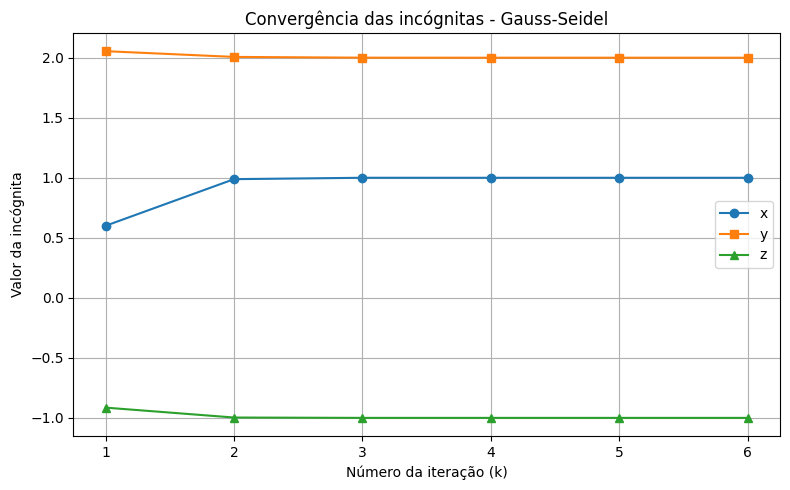

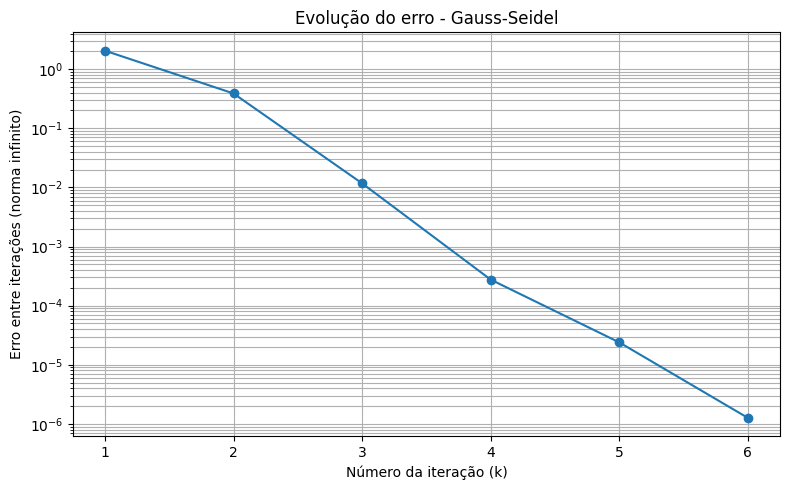

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Definir a matriz dos coeficientes e o vetor independente
A = np.array([
    [10, -1,  2],
    [-1, 11, -1],
    [ 2, -1, 10]
], dtype=float)

b = np.array([6, 22, -10], dtype=float)

# 2. Definir os parâmetros do método
tol = 1e-5
max_iter = 100
x = np.zeros(3)  # Aproximação inicial: (0, 0, 0)

# Listas para armazenar os resultados
historico = []
erros = []

# 3. Executar o método de Gauss-Seidel
for k in range(1, max_iter + 1):

    # Guardar os valores da iteração anterior
    x_ant = x.copy()

    # Atualizar x usando os valores anteriores de y e z
    x[0] = (6 + x_ant[1] - 2*x_ant[2]) / 10

    # Atualizar y usando o novo x e o z anterior
    x[1] = (22 + x[0] + x_ant[2]) / 11

    # Atualizar z usando os novos x e y
    x[2] = (-10 - 2*x[0] + x[1]) / 10

    # Calcular o erro pela norma infinito
    erro = np.max(np.abs(x - x_ant))

    # Armazenar os resultados da iteração
    historico.append([k, x[0], x[1], x[2], erro])
    erros.append(erro)

    # Verificar o critério de parada
    if erro < tol:
        break

# 4. Organizar os resultados em uma tabela
tabela = pd.DataFrame(
    historico,
    columns=["k", "x", "y", "z", "Erro infinito"]
)

print("Tabela de iterações:")
display(tabela.round(10))

print(f"Número de iterações: {k}")
print(f"Solução aproximada: x = {x[0]:.10f}, "
      f"y = {x[1]:.10f}, z = {x[2]:.10f}")
print(f"Erro final: {erro:.10e}")

# 5. Gráfico das incógnitas por iteração
plt.figure(figsize=(8, 5))
plt.plot(tabela["k"], tabela["x"], "o-", label="x")
plt.plot(tabela["k"], tabela["y"], "s-", label="y")
plt.plot(tabela["k"], tabela["z"], "^-", label="z")
plt.xlabel("Número da iteração (k)")
plt.ylabel("Valor da incógnita")
plt.title("Convergência das incógnitas - Gauss-Seidel")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 6. Gráfico do erro em escala logarítmica
plt.figure(figsize=(8, 5))
plt.semilogy(tabela["k"], tabela["Erro infinito"], "o-")
plt.xlabel("Número da iteração (k)")
plt.ylabel("Erro entre iterações (norma infinito)")
plt.title("Evolução do erro - Gauss-Seidel")
plt.grid(True, which="both")
plt.tight_layout()
plt.show()


In [ ]:
#O primeiro gráfico mostra a convergência das três incógnitas para os valores \(x=1\), \(y=2\) e \(z=-1\). O segundo gráfico demonstra a redução do erro entre iterações em escala logarítmica. Na sexta iteração, o erro fica inferior à tolerância de \(10^{-5}\), atendendo ao critério de parada estabelecido.